<center><h1>Hong_Brandon_HW8</h1></center>

Name: Brandon Hong
<br>
Github Username: bwhong
<br>
USC ID: 3091232124

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, roc_curve, silhouette_score, calinski_harabasz_score
from scipy.stats import mode
from scipy.special import softmax

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
column_names = ["ID", "Diagnosis"]
variables = ['radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
for i in np.arange(1,4):
    for j in variables:
        column_names.append(j + str(f"{i}"))
column_names[:5]

['ID', 'Diagnosis', 'radius1', 'texture1', 'perimeter1']

In [3]:
data = pd.read_csv(r'../data/wdbc.data', names= column_names)
data.head(3)

,ID,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,842302,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

In [4]:
M = 30
C_values = np.logspace(-3,1,10)
param_grid = {"svm__C": C_values}
X = data.drop(columns={'ID', 'Diagnosis'})
y = data['Diagnosis']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= 1)
linear_svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm",  LinearSVC(penalty='l1', dual=False, max_iter=20000))])
linear_svc_model = GridSearchCV(linear_svc_pipeline, param_grid, cv = StratifiedKFold(5, shuffle=True, random_state=1), scoring = 'accuracy', n_jobs = -1)
linear_svc_model.fit(X_train, y_train)
y_train_pred = linear_svc_model.predict(X_train)
y_train_score = linear_svc_model.decision_function(X_train)
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Precision Score:", precision_score(y_train, y_train_pred, pos_label='M'))
print("Training Recall Score:", recall_score(y_train, y_train_pred, pos_label='M'))
print("Training F1 Score:", f1_score(y_train, y_train_pred, pos_label='M'))
print("Training AUC Score:", roc_auc_score(y_train, y_train_score))
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

print()

y_test_pred = linear_svc_model.predict(X_test)
y_test_score = linear_svc_model.decision_function(X_test)
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))
print("Testing Precision Score:", precision_score(y_test, y_test_pred, pos_label='M'))
print("Testing Recall Score:", recall_score(y_test, y_test_pred, pos_label='M'))
print("Testing F1 Score:", f1_score(y_test, y_test_pred, pos_label='M'))
print("Testing AUC Score:", roc_auc_score(y_test, y_test_score))
print("Training Confusion Matrix")
print(confusion_matrix(y_test, y_test_pred))

Training Accuracy: 0.9846153846153847
Training Precision Score: 0.9880239520958084
Training Recall Score: 0.9705882352941176
Training F1 Score: 0.9792284866468842
Training AUC Score: 0.9978534571723426
Training Confusion Matrix:
[[283   2]
 [  5 165]]

Testing Accuracy: 0.9824561403508771
Testing Precision Score: 0.9761904761904762
Testing Recall Score: 0.9761904761904762
Testing F1 Score: 0.9761904761904762
Testing AUC Score: 0.9973544973544973
Training Confusion Matrix
[[71  1]
 [ 1 41]]


Text(0, 0.5, 'TPR')

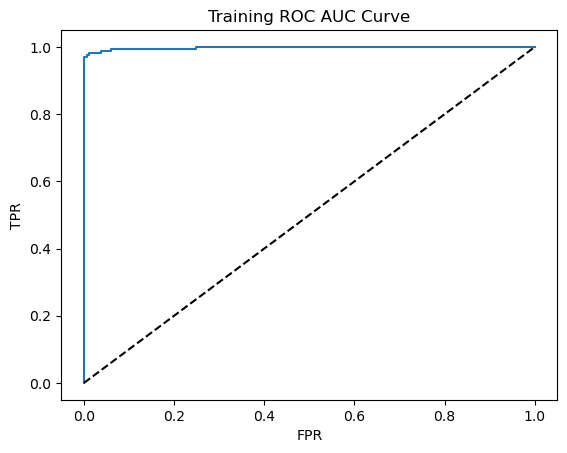

In [6]:
fpr, tpr, threshold = roc_curve(y_train, y_train_score, pos_label='M')
plt.plot(fpr, tpr, label = 'Training ROC')
plt.plot([0, 1], [0, 1], "k--")
plt.title("Training ROC AUC Curve")
plt.xlabel('FPR')
plt.ylabel('TPR')

Text(0, 0.5, 'TPR')

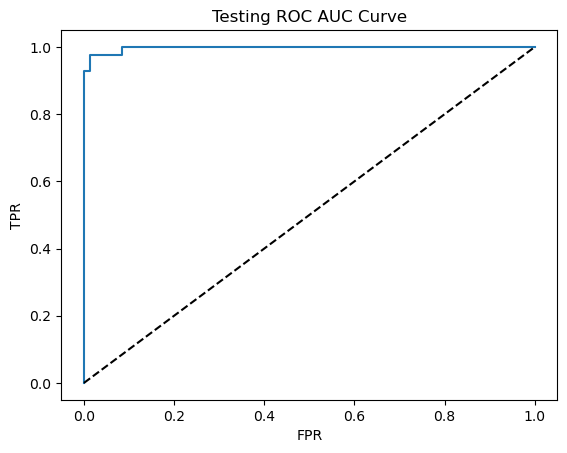

In [7]:
fpr, tpr, threshold = roc_curve(y_test, y_test_score, pos_label='M')
plt.plot(fpr, tpr, label = 'Testing ROC')
plt.plot([0, 1], [0, 1], "k--")
plt.title("Testing ROC AUC Curve")
plt.xlabel('FPR')
plt.ylabel('TPR')

In [8]:
training_accuracy_score_list = []
training_precision_score_list = []
training_recall_score_list = []
training_f1_score_list = []
training_auc_score_list = []
testing_accuracy_score_list = []
testing_precision_score_list = []
testing_recall_score_list = []
testing_f1_score_list = []
testing_auc_score_list = []

for i in np.arange(M):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= i)
    linear_svc_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm",  LinearSVC(penalty='l1', dual=False, max_iter=20000))])
    linear_svc_model = GridSearchCV(linear_svc_pipeline, param_grid, cv = StratifiedKFold(5, shuffle=True, random_state=i), scoring = 'accuracy', n_jobs = -1)
    linear_svc_model.fit(X_train, y_train)
    y_train_pred = linear_svc_model.predict(X_train)
    y_train_score = linear_svc_model.decision_function(X_train)
    training_accuracy_score_list.append(accuracy_score(y_train, y_train_pred))
    training_precision_score_list.append(precision_score(y_train, y_train_pred, pos_label='M'))
    training_recall_score_list.append(recall_score(y_train, y_train_pred, pos_label='M'))
    training_f1_score_list.append(f1_score(y_train, y_train_pred, pos_label='M'))
    training_auc_score_list.append(roc_auc_score(y_train, y_train_score))

    y_test_pred = linear_svc_model.predict(X_test)
    y_test_score = linear_svc_model.decision_function(X_test)
    testing_accuracy_score_list.append(accuracy_score(y_test, y_test_pred))
    testing_precision_score_list.append(precision_score(y_test, y_test_pred, pos_label='M'))
    testing_recall_score_list.append(recall_score(y_test, y_test_pred, pos_label='M'))
    testing_f1_score_list.append(f1_score(y_test, y_test_pred, pos_label='M'))
    testing_auc_score_list.append(roc_auc_score(y_test, y_test_score))

print("Training Average Accuracy:", np.mean(training_accuracy_score_list))
print("Training Average Precision Score:", np.mean(training_precision_score_list))
print("Training Average Recall Score:", np.mean(training_recall_score_list))
print("Training Average F1 Score:", np.mean(training_f1_score_list))
print("Training Average AUC Score:", np.mean(training_auc_score_list))

print()

print("Testing Average Accuracy:", np.mean(testing_accuracy_score_list))
print("Testing Average Precision Score:", np.mean(testing_precision_score_list))
print("Testing Average Recall Score:", np.mean(testing_recall_score_list))
print("Testing Average F1 Score:", np.mean(testing_f1_score_list))
print("Testing Average AUC Score:", np.mean(testing_auc_score_list))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Training Average Accuracy: 0.9844688644688645
Training Average Precision Score: 0.9895934286579461
Training Average Recall Score: 0.968627450980392
Training Average F1 Score: 0.9789784699675715
Training Average AUC Score: 0.9969810801513588

Testing Average Accuracy: 0.9687134502923976
Testing Average Precision Score: 0.9742140957597567
Testing Average Recall Score: 0.9404761904761902
Testing Average F1 Score: 0.9566306930403132
Testing Average AUC Score: 0.9931106701940036


#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [105]:
M = 30
C_values = np.logspace(-3,0,10)
param_grid = {"svm__C": C_values}
X = data.drop(columns={'ID', 'Diagnosis'})
y = data['Diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= 1)
X_train_labeled, X_train_unlabeled, y_train_labeled, y_train_unlabeled = train_test_split(X_train, y_train, test_size=.5, stratify = y_train, random_state= 1)

In [106]:
linear_svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm",  LinearSVC(penalty='l1', dual=False, max_iter=20000))])
linear_svc_model = GridSearchCV(linear_svc_pipeline, param_grid, cv = StratifiedKFold(5, shuffle=True, random_state=1), scoring = 'accuracy', n_jobs = -1)
linear_svc_model.fit(X_train_labeled, y_train_labeled)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm',
                                        LinearSVC(dual=False, max_iter=20000,
                                                  penalty='l1'))]),
             n_jobs=-1,
             param_grid={'svm__C': array([0.001     , 0.00215443, 0.00464159, 0.01      , 0.02154435,
       0.04641589, 0.1       , 0.21544347, 0.46415888, 1.        ])},
             scoring='accuracy')

##### (B)

In [107]:
while len(X_train_unlabeled) > 0:
    linear_svc_model.fit(X_train_labeled, y_train_labeled)
    distance = np.abs(linear_svc_model.decision_function(X_train_unlabeled))
    closest_point = np.argsort(-distance)[:1]
    closest_point_index = X_train_unlabeled.index[closest_point]
    X_train_labeled = pd.concat([X_train_labeled, X_train_unlabeled.loc[closest_point_index]])
    y_train_labeled = pd.concat([y_train_labeled, pd.Series(linear_svc_model.predict(X_train_unlabeled.loc[closest_point_index]),index=closest_point_index)])
    X_train_unlabeled = X_train_unlabeled.drop(closest_point_index)
    y_train_unlabeled = y_train_unlabeled.drop(closest_point_index)
#final run
linear_svc_model.fit(X_train_labeled, y_train_labeled)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm',
                                        LinearSVC(dual=False, max_iter=20000,
                                                  penalty='l1'))]),
             n_jobs=-1,
             param_grid={'svm__C': array([0.001     , 0.00215443, 0.00464159, 0.01      , 0.02154435,
       0.04641589, 0.1       , 0.21544347, 0.46415888, 1.        ])},
             scoring='accuracy')

In [108]:
y_train_pred = linear_svc_model.predict(X_train)
y_train_score = linear_svc_model.decision_function(X_train)
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Precision Score:", precision_score(y_train, y_train_pred, pos_label='M'))
print("Training Recall Score:", recall_score(y_train, y_train_pred, pos_label='M'))
print("Training F1 Score:", f1_score(y_train, y_train_pred, pos_label='M'))
print("Training AUC Score:", roc_auc_score(y_train, y_train_score))
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

print()

y_test_pred = linear_svc_model.predict(X_test)
y_test_score = linear_svc_model.decision_function(X_test)
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))
print("Testing Precision Score:", precision_score(y_test, y_test_pred, pos_label='M'))
print("Testing Recall Score:", recall_score(y_test, y_test_pred, pos_label='M'))
print("Testing F1 Score:", f1_score(y_test, y_test_pred, pos_label='M'))
print("Testing AUC Score:", roc_auc_score(y_test, y_test_score))
print("Testing Confusion Matrix")
print(confusion_matrix(y_test, y_test_pred))

Training Accuracy: 0.978021978021978
Training Precision Score: 0.9938271604938271
Training Recall Score: 0.9470588235294117
Training F1 Score: 0.9698795180722891
Training AUC Score: 0.9907327141382869
Training Confusion Matrix:
[[284   1]
 [  9 161]]

Testing Accuracy: 0.956140350877193
Testing Precision Score: 0.9512195121951219
Testing Recall Score: 0.9285714285714286
Testing F1 Score: 0.9397590361445783
Testing AUC Score: 0.9957010582010583
Testing Confusion Matrix
[[70  2]
 [ 3 39]]


Text(0, 0.5, 'TPR')

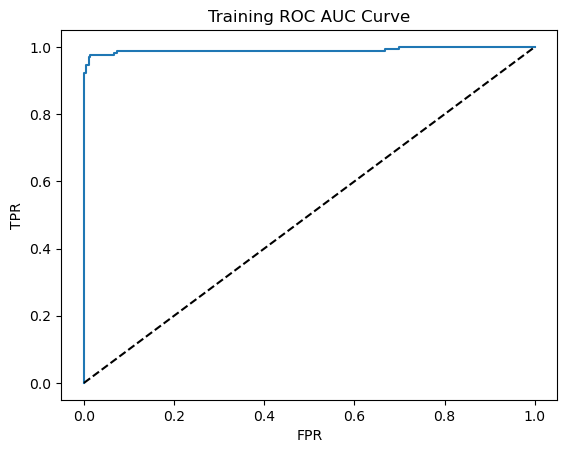

In [109]:
fpr, tpr, threshold = roc_curve(y_train, y_train_score, pos_label='M')
plt.plot(fpr, tpr, label = 'Training ROC')
plt.plot([0, 1], [0, 1], "k--")
plt.title("Training ROC AUC Curve")
plt.xlabel('FPR')
plt.ylabel('TPR')

Text(0, 0.5, 'TPR')

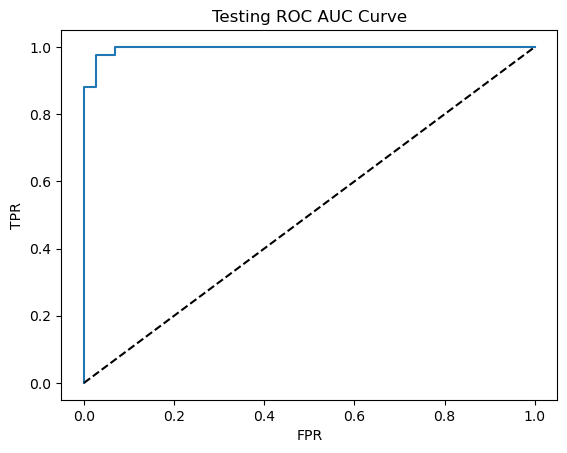

In [110]:
fpr, tpr, threshold = roc_curve(y_test, y_test_score, pos_label='M')
plt.plot(fpr, tpr, label = 'Testing ROC')
plt.plot([0, 1], [0, 1], "k--")
plt.title("Testing ROC AUC Curve")
plt.xlabel('FPR')
plt.ylabel('TPR')

### Monte Carlo

In [111]:
training_accuracy_score_list = []
training_precision_score_list = []
training_recall_score_list = []
training_f1_score_list = []
training_auc_score_list = []
testing_accuracy_score_list = []
testing_precision_score_list = []
testing_recall_score_list = []
testing_f1_score_list = []
testing_auc_score_list = []

for run in np.arange(M):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= 1)
    X_train_labeled, X_train_unlabeled, y_train_labeled, y_train_unlabeled = train_test_split(X_train, y_train, test_size=.5, stratify = y_train, random_state= run)

    linear_svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm",  LinearSVC(penalty='l1', dual=False, max_iter=20000))])
    linear_svc_model = GridSearchCV(linear_svc_pipeline, param_grid, cv = StratifiedKFold(5, shuffle=True, random_state=1), scoring = 'accuracy', n_jobs = -1)
    linear_svc_model.fit(X_train_labeled, y_train_labeled)

    while len(X_train_unlabeled) > 0:
        linear_svc_model.fit(X_train_labeled, y_train_labeled)
        distance = np.abs(linear_svc_model.decision_function(X_train_unlabeled))
        closest_point = np.argsort(-distance)[:1]
        closest_point_index = X_train_unlabeled.index[closest_point]
        X_train_labeled = pd.concat([X_train_labeled, X_train_unlabeled.loc[closest_point_index]])
        y_train_labeled = pd.concat([y_train_labeled, pd.Series(linear_svc_model.predict(X_train_unlabeled.loc[closest_point_index]),index=closest_point_index)])
        X_train_unlabeled = X_train_unlabeled.drop(closest_point_index)
        y_train_unlabeled = y_train_unlabeled.drop(closest_point_index)
    #final run
    linear_svc_model.fit(X_train_labeled, y_train_labeled)

    y_train_pred = linear_svc_model.predict(X_train)
    y_train_score = linear_svc_model.decision_function(X_train)
    training_accuracy_score_list.append(accuracy_score(y_train, y_train_pred))
    training_precision_score_list.append(precision_score(y_train, y_train_pred, pos_label='M'))
    training_recall_score_list.append(recall_score(y_train, y_train_pred, pos_label='M'))
    training_f1_score_list.append(f1_score(y_train, y_train_pred, pos_label='M'))
    training_auc_score_list.append(roc_auc_score(y_train, y_train_score))
    
    y_test_pred = linear_svc_model.predict(X_test)
    y_test_score = linear_svc_model.decision_function(X_test)
    testing_accuracy_score_list.append(accuracy_score(y_test, y_test_pred))
    testing_precision_score_list.append(precision_score(y_test, y_test_pred, pos_label='M'))
    testing_recall_score_list.append(recall_score(y_test, y_test_pred, pos_label='M'))
    testing_f1_score_list.append(f1_score(y_test, y_test_pred, pos_label='M'))
    testing_auc_score_list.append(roc_auc_score(y_test, y_test_score))
    
print("Training Average Accuracy:", np.mean(training_accuracy_score_list))
print("Training Average Precision Score:", np.mean(training_precision_score_list))
print("Training Average Recall Score:", np.mean(training_recall_score_list))
print("Training Average F1 Score:", np.mean(training_f1_score_list))
print("Training Average AUC Score:", np.mean(training_auc_score_list))
    
print()
    
print("Testing Average Accuracy:", np.mean(testing_accuracy_score_list))
print("Testing Average Precision Score:", np.mean(testing_precision_score_list))
print("Testing Average Recall Score:", np.mean(testing_recall_score_list))
print("Testing Average F1 Score:", np.mean(testing_f1_score_list))
print("Testing Average AUC Score:", np.mean(testing_auc_score_list))

Training Average Accuracy: 0.9773626373626373
Training Average Precision Score: 0.9899211618192848
Training Average Recall Score: 0.9492156862745097
Training Average F1 Score: 0.9690389118618101
Training Average AUC Score: 0.9935878912968696

Testing Average Accuracy: 0.9646198830409354
Testing Average Precision Score: 0.9651819451110433
Testing Average Recall Score: 0.938095238095238
Testing Average F1 Score: 0.9512810983203409
Testing Average AUC Score: 0.9967261904761905


Exception ignored in: <function ResourceTracker.__del__ at 0x106b71bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106789bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1052e1bc0>
Traceback (most recent call last

#### (iii) Unsupervised Learning

In [132]:
X = data.drop(columns={'ID', 'Diagnosis'})
y = data['Diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= 1)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

##### (A)

In [133]:
kmeans = KMeans(n_clusters = 2, init="random").fit(X_train_scaled)
labels = kmeans.labels_
ch_score = calinski_harabasz_score(X_train_scaled, labels)
print(ch_score)

224.18509655040614


In [134]:
kmeans2 = KMeans(n_clusters = 2, init="random").fit(X_train_scaled)
labels = kmeans2.labels_
ch_score = calinski_harabasz_score(X_train_scaled, labels)
print(ch_score)

224.18760488674152


In [135]:
kmeans3 = KMeans(n_clusters = 2, init="random").fit(X_train_scaled)
labels = kmeans3.labels_
ch_score = calinski_harabasz_score(X_train_scaled, labels)
print(ch_score)

224.18760488674152


In [136]:
kmeans4 = KMeans(n_clusters = 2, init="random").fit(X_train_scaled)
labels = kmeans4.labels_
ch_score = calinski_harabasz_score(X_train_scaled, labels)
print(ch_score)

224.18509655040614


elaborate more

By repeating this algorithm with random initilization, we always receive the same CH Score. This was to reduce the risk of selecting a local minimum. This does not guarentee that the global minimum was found.

##### (B)

In [137]:
kmeans = KMeans(n_clusters = 2, init="random", random_state = 1).fit(X_train_scaled)
labels = kmeans.labels_
train_distance = kmeans.transform(X_train_scaled)

In [138]:
cluster_majority_index = {}
for k in np.arange(2):
    members = np.where(labels == k)[0]
    member_order = np.argsort(train_distance[members, k])
    cluster_majority_index[k] = members[member_order[:30]]

cluster_label_majority = {}
for key, value in cluster_majority_index.items():
    cluster_label_majority[key] = y_train.iloc[value].value_counts().idxmax()

In [139]:
y_train_pred = pd.Series(labels).map(cluster_label_majority).to_numpy()

for key, value in cluster_label_majority.items():
    if value == 'M':
        M = key
y_train_score = softmax(-train_distance, axis=1)[:, 1]

In [140]:
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Precision Score:", precision_score(y_train, y_train_pred, pos_label='M'))
print("Training Recall Score:", recall_score(y_train, y_train_pred, pos_label='M'))
print("Training F1 Score:", f1_score(y_train, y_train_pred, pos_label='M'))
print("Training AUC Score:", roc_auc_score(y_train, y_train_score))
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

Training Accuracy: 0.9032967032967033
Training Precision Score: 0.9144736842105263
Training Recall Score: 0.8176470588235294
Training F1 Score: 0.8633540372670807
Training AUC Score: 0.9725902992776058
Training Confusion Matrix:
[[272  13]
 [ 31 139]]


Text(0, 0.5, 'TPR')

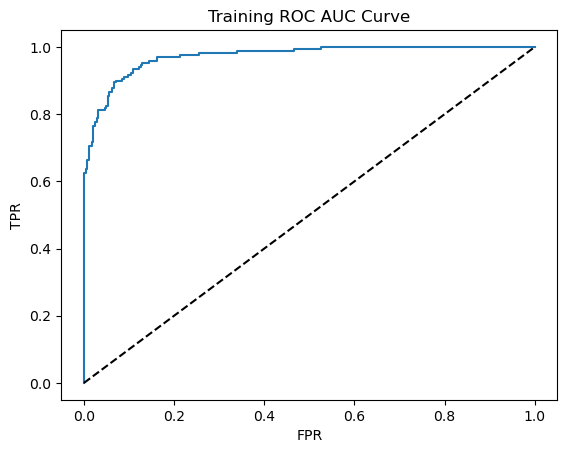

In [141]:
fpr, tpr, threshold = roc_curve(y_train, y_train_score, pos_label='M')
plt.plot(fpr, tpr, label = 'Training ROC')
plt.plot([0, 1], [0, 1], "k--")
plt.title("Training ROC AUC Curve")
plt.xlabel('FPR')
plt.ylabel('TPR')

##### (C)

In [142]:
test_distance = kmeans.transform(X_test_scaled)
y_test_pred_clusters = kmeans.predict(X_test_scaled)
y_test_pred = pd.Series(y_test_pred_clusters).map(cluster_label_majority).to_numpy()

for key, value in cluster_label_majority.items():
    if value == 'M':
        M = key
y_test_score = softmax(-test_distance, axis=1)[:, M]

In [143]:
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))
print("Testing Precision Score:", precision_score(y_test, y_test_pred, pos_label='M'))
print("Testing Recall Score:", recall_score(y_test, y_test_pred, pos_label='M'))
print("Testing F1 Score:", f1_score(y_test, y_test_pred, pos_label='M'))
print("Testing AUC Score:", roc_auc_score(y_test, y_test_score))
print("Training Confusion Matrix")
print(confusion_matrix(y_test, y_test_pred))

Testing Accuracy: 0.9210526315789473
Testing Precision Score: 0.9459459459459459
Testing Recall Score: 0.8333333333333334
Testing F1 Score: 0.8860759493670886
Testing AUC Score: 0.9755291005291006
Training Confusion Matrix
[[70  2]
 [ 7 35]]


Text(0, 0.5, 'TPR')

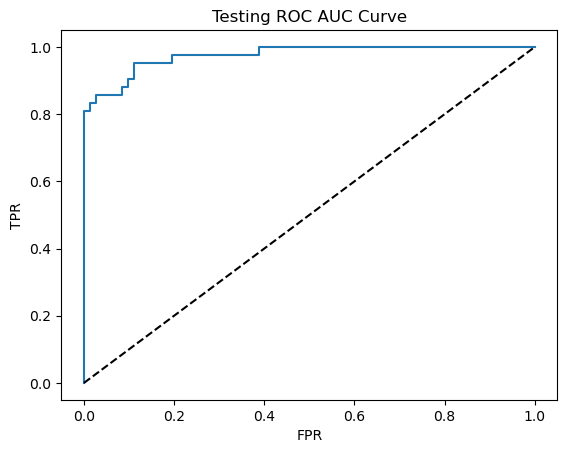

In [144]:
fpr, tpr, threshold = roc_curve(y_test, y_test_score, pos_label='M')
plt.plot(fpr, tpr, label = 'Testing ROC')
plt.plot([0, 1], [0, 1], "k--")
plt.title("Testing ROC AUC Curve")
plt.xlabel('FPR')
plt.ylabel('TPR')

### Monte Carlo

In [150]:
training_accuracy_score_list = []
training_precision_score_list = []
training_recall_score_list = []
training_f1_score_list = []
training_auc_score_list = []
testing_accuracy_score_list = []
testing_precision_score_list = []
testing_recall_score_list = []
testing_f1_score_list = []
testing_auc_score_list = []

for i in np.arange(M):
    #training
    X = data.drop(columns={'ID', 'Diagnosis'})
    y = data['Diagnosis']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= i)

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    kmeans = KMeans(n_clusters = 2, init="random", random_state = i).fit(X_train_scaled)
    labels = kmeans.labels_
    train_distance = kmeans.transform(X_train_scaled)

    cluster_majority_index = {}
    for k in np.arange(2):
        members = np.where(labels == k)[0]
        member_order = np.argsort(train_distance[members, k])
        cluster_majority_index[k] = members[member_order[:30]]

    cluster_label_majority = {}
    for key, value in cluster_majority_index.items():
        cluster_label_majority[key] = y_train.iloc[value].value_counts().idxmax()

    y_train_pred = pd.Series(labels).map(cluster_label_majority).to_numpy()

    for key, value in cluster_label_majority.items():
        if value == 'M':
            m = key
    y_train_score = softmax(-train_distance, axis=1)[:, m]

    #testing
    test_distance = kmeans.transform(X_test_scaled)
    y_test_pred_clusters = kmeans.predict(X_test_scaled)
    y_test_pred = pd.Series(y_test_pred_clusters).map(cluster_label_majority).to_numpy()

    for key, value in cluster_label_majority.items():
        if value == 'M':
            m = key
    y_test_score = softmax(-test_distance, axis=1)[:, m]
    
    training_accuracy_score_list.append(accuracy_score(y_train, y_train_pred))
    training_precision_score_list.append(precision_score(y_train, y_train_pred, pos_label='M'))
    training_recall_score_list.append(recall_score(y_train, y_train_pred, pos_label='M'))
    training_f1_score_list.append(f1_score(y_train, y_train_pred, pos_label='M'))
    training_auc_score_list.append(roc_auc_score(y_train, y_train_score))

    testing_accuracy_score_list.append(accuracy_score(y_test, y_test_pred))
    testing_precision_score_list.append(precision_score(y_test, y_test_pred, pos_label='M'))
    testing_recall_score_list.append(recall_score(y_test, y_test_pred, pos_label='M'))
    testing_f1_score_list.append(f1_score(y_test, y_test_pred, pos_label='M'))
    testing_auc_score_list.append(roc_auc_score(y_test, y_test_score))

print("Training Average Accuracy:", np.mean(training_accuracy_score_list))
print("Training Average Precision Score:", np.mean(training_precision_score_list))
print("Training Average Recall Score:", np.mean(training_recall_score_list))
print("Training Average F1 Score:", np.mean(training_f1_score_list))
print("Training Average AUC Score:", np.mean(training_auc_score_list))

print()

print("Testing Average Accuracy:", np.mean(testing_accuracy_score_list))
print("Testing Average Precision Score:", np.mean(testing_precision_score_list))
print("Testing Average Recall Score:", np.mean(testing_recall_score_list))
print("Testing Average F1 Score:", np.mean(testing_f1_score_list))
print("Testing Average AUC Score:", np.mean(testing_auc_score_list))

Training Average Accuracy: 0.9102564102564104
Training Average Precision Score: 0.9236899595508661
Training Average Recall Score: 0.8286274509803921
Training Average F1 Score: 0.8733809831481139
Training Average AUC Score: 0.974841417268662

Testing Average Accuracy: 0.9055555555555557
Testing Average Precision Score: 0.9097176869871967
Testing Average Recall Score: 0.8269841269841269
Testing Average F1 Score: 0.8651565833722785
Testing Average AUC Score: 0.9718364197530865


#### (iv) Spectral Clustering

In [285]:
X = data.drop(columns={'ID', 'Diagnosis'})
y = data['Diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify = y, random_state= 1)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [286]:
spectral_clustering = SpectralClustering(n_clusters = 2, affinity= 'rbf', random_state = 1, gamma=1)
spectral_clustering.fit_predict(X_train_scaled)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

#### (iv) Compare

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [168]:
column_names = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
banknotes = pd.read_csv(r'../data/data_banknote_authentication.txt', names = column_names)
banknotes.head(3)

,variance,skewness,curtosis,entropy,class
0,3.6216,8.6661,-2.8073,-0.44699,0
1,4.5459,8.1674,-2.4586,-1.46210,0
2,3.8660,-2.6383,1.9242,0.10645,0


In [169]:
banknotes.shape

(1372, 5)

In [170]:
train_data, test_data = train_test_split(banknotes, test_size=472)

In [171]:
train_data.shape, test_data.shape

((900, 5), (472, 5))

### (b) Repeat each of the following two procedures 50 times

In [269]:
M = 50
C_values = np.logspace(-2,1,10)
param_grid = {"svm__C": C_values}

#### (i) Passive

In [ ]:
all_passive_learning_test_errors = []
for run in np.arange(M):
    while True:
        train_data_shuffled = train_data.sample(frac = 1)
        X_train_shuffled = train_data_shuffled.drop(columns = {'class'})
        y_train_shuffled = train_data_shuffled['class']
        X_test = test_data.drop(columns = {'class'})
        y_test = test_data['class']
        if y_train_shuffled[:10].value_counts().min() == 5:
            break
    test_errors = []
    for i in np.arange(10, 910, 10):
        train_X_pool = X_train_shuffled[:i]
        train_y_pool = y_train_shuffled[:i]

        linear_svc_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm",  LinearSVC(penalty='l1', dual=False, max_iter=30000))])
        
        linear_svc_model = GridSearchCV(linear_svc_pipeline, param_grid, cv = StratifiedKFold(5, shuffle=True, random_state=42), scoring = 'accuracy', n_jobs = -1)
        linear_svc_model.fit(train_X_pool, train_y_pool)
        y_test_pred = linear_svc_model.predict(X_test)
        test_errors.append(1 - accuracy_score(y_test, y_test_pred))
    all_passive_learning_test_errors.append(test_errors)

In [271]:
passive_learning_test_error_df = pd.DataFrame(all_passive_learning_test_errors)
passive_learning_test_error_df.head(3)

,0,1,2,3,4,5,6,7,8,9,...,80,81,82,83,84,85,86,87,88,89
0,0.019068,0.023305,0.025424,0.023305,0.029661,0.027542,0.027542,0.027542,0.025424,0.027542,...,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475
1,0.144068,0.025424,0.008475,0.042373,0.048729,0.031780,0.027542,0.010593,0.025424,0.019068,...,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475
2,0.250000,0.167373,0.033898,0.029661,0.014831,0.023305,0.023305,0.021186,0.010593,0.016949,...,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475


#### (ii) Active

In [ ]:
all_active_learning_test_errors = []

for run in np.arange(M):
    test_errors = []

    while True:
        train_data_shuffled = train_data.sample(frac = 1)
        X_train_shuffled = train_data_shuffled.drop(columns = {'class'})
        y_train_shuffled = train_data_shuffled['class']
        X_test = test_data.drop(columns = {'class'})
        y_test = test_data['class']
        train_X_pool = X_train_shuffled.iloc[:10]
        train_y_pool = y_train_shuffled.iloc[:10]
        if train_y_pool.value_counts().min() == 5:
            break
    remaining_train_X_pool = X_train_shuffled.iloc[10:]
    remaining_train_y_pool = y_train_shuffled.iloc[10:]

    for i in np.arange(10, 910, 10):
        linear_svc_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm",  LinearSVC(penalty='l1', dual=False, max_iter=30000))])
        
        linear_svc_model = GridSearchCV(linear_svc_pipeline, param_grid, cv = StratifiedKFold(5, shuffle=True, random_state=42), scoring = 'accuracy', n_jobs = -1)
        linear_svc_model.fit(train_X_pool, train_y_pool)

        y_test_pred = linear_svc_model.predict(X_test)
        test_errors.append(1 - accuracy_score(y_test, y_test_pred))

        if len(remaining_train_X_pool) == 0:
            break

        distance = np.abs(linear_svc_model.decision_function(remaining_train_X_pool))
        closest_10_points = np.argsort(distance)[:10]
        closest_10_points_index = remaining_train_X_pool.index[closest_10_points]

        train_X_pool = pd.concat([train_X_pool, remaining_train_X_pool.loc[closest_10_points_index]])
        train_y_pool = pd.concat([train_y_pool, remaining_train_y_pool.loc[closest_10_points_index]])
        remaining_train_X_pool = remaining_train_X_pool.drop(closest_10_points_index)
        remaining_train_y_pool = remaining_train_y_pool.drop(closest_10_points_index)
    all_active_learning_test_errors.append(test_errors)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
Exception ignored in: <function ResourceTracker.__del__ at 0x103f45bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106df1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  F

KeyboardInterrupt: 

In [ ]:
active_learning_test_error_df = pd.DataFrame(all_active_learning_test_errors)
active_learning_test_error_df.head(3)

,0,1,2,3,4,5,6,7,8,9,...,80,81,82,83,84,85,86,87,88,89
0,0.161017,0.033898,0.040254,0.023305,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,...,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475
1,0.161017,0.033898,0.040254,0.023305,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,...,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475
2,0.161017,0.033898,0.040254,0.023305,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,...,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475,0.008475


### (c) Average the 50 test errors

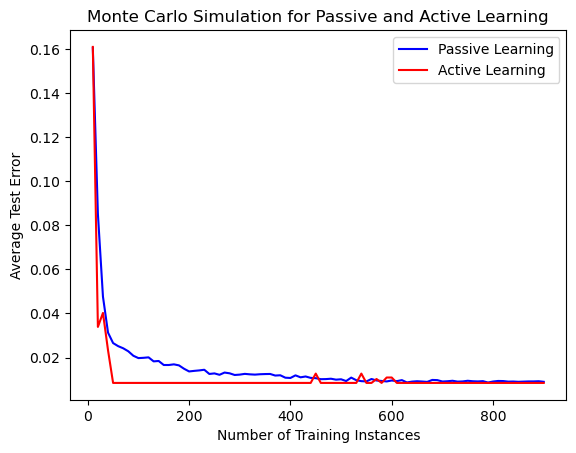

In [268]:
plt.plot(np.arange(10,910,10), passive_learning_test_error_df.mean(axis = 0), color = 'blue', label = 'Passive Learning')
plt.plot(np.arange(10,910,10), active_learning_test_error_df.mean(axis = 0), color = 'red', label = 'Active Learning')
plt.title('Monte Carlo Simulation for Passive and Active Learning')
plt.xlabel('Number of Training Instances')
plt.ylabel('Average Test Error')
plt.legend()